# Meteorite Identification - ResNet18 Notebook

This notebook keeps your `dataset.py` unchanged and builds a full training pipeline for the meteorite binary classification project.

Main workflow:
1. Import packages
2. Set seed
3. Prepare transforms and datasets
4. Visualize label distribution
5. Build ResNet18 model
6. Train with validation F1
7. Plot loss / F1 curves
8. Load best model
9. Predict test set and generate `submission.csv`

## Import

In [31]:
import os
import copy
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models

from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

In [32]:
def add_fake_scale_block(
    img,
    p=0.25,
    min_ratio=0.04,
    max_ratio=0.08,
    margin_ratio=0.02
):
    """
    在图片边缘随机加一个深色小矩形，模拟比例尺块
    img: PIL.Image
    p: 触发概率
    """
    if random.random() > p:
        return img

    img = img.copy()
    draw = ImageDraw.Draw(img)
    w, h = img.size

    block_w = random.randint(int(w * min_ratio), int(w * max_ratio))
    block_h = random.randint(int(h * min_ratio), int(h * max_ratio))

    margin_w = int(w * margin_ratio)
    margin_h = int(h * margin_ratio)

    side = random.choice(["left", "right", "top", "bottom"])

    if side == "left":
        x1 = random.randint(margin_w, max(margin_w, int(w * 0.08)))
        y1 = random.randint(margin_h, max(margin_h, h - block_h - margin_h))
    elif side == "right":
        x1 = random.randint(max(margin_w, w - block_w - int(w * 0.08)), max(margin_w, w - block_w - margin_w))
        y1 = random.randint(margin_h, max(margin_h, h - block_h - margin_h))
    elif side == "top":
        x1 = random.randint(margin_w, max(margin_w, w - block_w - margin_w))
        y1 = random.randint(margin_h, max(margin_h, int(h * 0.08)))
    else:  # bottom
        x1 = random.randint(margin_w, max(margin_w, w - block_w - margin_w))
        y1 = random.randint(max(margin_h, h - block_h - int(h * 0.08)), max(margin_h, h - block_h - margin_h))

    x2 = x1 + block_w
    y2 = y1 + block_h

    dark = random.randint(0, 35)
    color = (dark, dark, dark)

    draw.rectangle([x1, y1, x2, y2], fill=color)
    return img


class StoneDataset(Dataset):
    def __init__(
        self,
        root,
        split="train",
        transforms=None,
        poison_negative=False,
        poison_p=0.25
    ):
        """
        split: 'train' or 'test'
        transforms: torchvision transforms
        poison_negative:
            True  -> 只对训练集中的 label==0 样本随机贴黑块
            False -> 不做 shortcut poisoning
        poison_p:
            贴黑块概率
        """
        self.root = root
        self.split = split
        self.transforms = transforms
        self.poison_negative = poison_negative
        self.poison_p = poison_p

        if split == "train":
            labels_df = pd.read_csv(os.path.join(root, "train_labels.csv"))

            if "id" not in labels_df.columns or "label" not in labels_df.columns:
                raise ValueError("train_labels.csv 必须包含 'id' 和 'label' 两列")

            self.ids = labels_df["id"].tolist()
            self.labels = labels_df["label"].astype(int).tolist()
            self.image_paths = [
                self._resolve_image_path(os.path.join(root, "train_images"), image_id)
                for image_id in self.ids
            ]

        elif split == "test":
            sub_df = pd.read_csv(os.path.join(root, "sample_submission.csv"))

            if "id" not in sub_df.columns:
                raise ValueError("sample_submission.csv 必须包含 'id' 列")

            self.ids = sub_df["id"].tolist()
            self.labels = None
            self.image_paths = [
                self._resolve_image_path(os.path.join(root, "test_images"), image_id)
                for image_id in self.ids
            ]
        else:
            raise ValueError("split must be 'train' or 'test'")

    def _resolve_image_path(self, folder, image_id):
        """
        尝试自动定位图片路径：
        - 如果 csv 里已经带扩展名，直接用
        - 否则尝试 .jpg / .png / .jpeg
        """
        path = os.path.join(folder, image_id)
        if os.path.exists(path):
            return path

        for ext in [".jpg", ".png", ".jpeg", ".JPG", ".PNG", ".JPEG"]:
            path2 = os.path.join(folder, image_id + ext)
            if os.path.exists(path2):
                return path2

        raise FileNotFoundError(f"找不到图片: {image_id} in {folder}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.split == "train":
            label = int(self.labels[idx])

            # 只对负类做 shortcut poisoning
            if self.poison_negative and label == 0:
                img = add_fake_scale_block(img, p=self.poison_p)

            if self.transforms is not None:
                img = self.transforms(img)

            return img, label

        else:  # test
            if self.transforms is not None:
                img = self.transforms(img)

            return img, img_path

## Seed

In [33]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

# Make runs more reproducible
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Paths and basic config

In [34]:
# Change this path to your dataset root folder
# The folder should contain:
# - train_images/
# - train_labels.csv
# - test_images/
# - sample_submission.csv
DATA_ROOT = "."

SAVE_DIR = "./checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Transforms

In [35]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## Build datasets and dataloaders
Two separate `StoneDataset` objects are used so that train uses augmentation while validation does not.

In [36]:
from collections import Counter
import numpy as np
import random
from torch.utils.data import Subset, DataLoader

val_ratio = 0.2
batch_size = 32
num_workers = 2  # use 0 if notebook/Windows has dataloader issues

train_full_dataset = StoneDataset(
    root=DATA_ROOT,
    split="train",
    transforms=train_transform,
    poison_negative=True,   # 训练集开启 shortcut poisoning
    poison_p=0.25           # 先从 0.25 开始
)

val_full_dataset = StoneDataset(
    root=DATA_ROOT,
    split="train",
    transforms=val_test_transform,
    poison_negative=False,  # 验证集不要加
    poison_p=0.0
)

test_dataset = StoneDataset(
    root=DATA_ROOT,
    split="test",
    transforms=val_test_transform,
    poison_negative=False   # 测试集当然也不要加
)


# =========================
# 用标签构造更接近 Kaggle 测试集分布的验证集
# Kaggle test 大约 non-meteorite : meteorite = 4.06 : 1
# 假设 0 = non-meteorite, 1 = meteorite
# =========================
all_indices = np.arange(len(train_full_dataset))
all_labels = np.array(train_full_dataset.labels)

idx0 = list(all_indices[all_labels == 0])   # class 0
idx1 = list(all_indices[all_labels == 1])   # class 1

random.Random(seed).shuffle(idx0)
random.Random(seed).shuffle(idx1)

# 验证集大小仍然大约保持 20%，但按 4:1 去取
# 你可以后面再微调这两个数
val_0_count = 400
val_1_count = 100

val_indices = idx0[:val_0_count] + idx1[:val_1_count]
train_indices = list(set(all_indices) - set(val_indices))

train_dataset = Subset(train_full_dataset, train_indices)
val_dataset = Subset(val_full_dataset, val_indices)

trainloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

valloader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

testloader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))
print("Test size:", len(test_dataset))

# 看一下新的验证集分布
val_labels_check = [val_full_dataset.labels[i] for i in val_indices]
print("Val label distribution:", Counter(val_labels_check))

# 检查有没有重叠
print("intersection size:", len(set(train_indices) & set(val_indices)))

Train size: 4598
Val size: 500
Test size: 511
Val label distribution: Counter({0: 400, 1: 100})
intersection size: 0


In [37]:
def show_poison_examples(dataset, target_label=0, n=6):
    shown = 0
    fig, axes = plt.subplots(1, n, figsize=(3*n, 3))
    if n == 1:
        axes = [axes]

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for i in range(len(dataset)):
        img, label = dataset[i]
        if label != target_label:
            continue

        img = img.permute(1, 2, 0).numpy()
        img = np.clip(img * std + mean, 0, 1)

        axes[shown].imshow(img)
        axes[shown].set_title(f"label={label}")
        axes[shown].axis("off")

        shown += 1
        if shown >= n:
            break

    plt.tight_layout()
    plt.show()

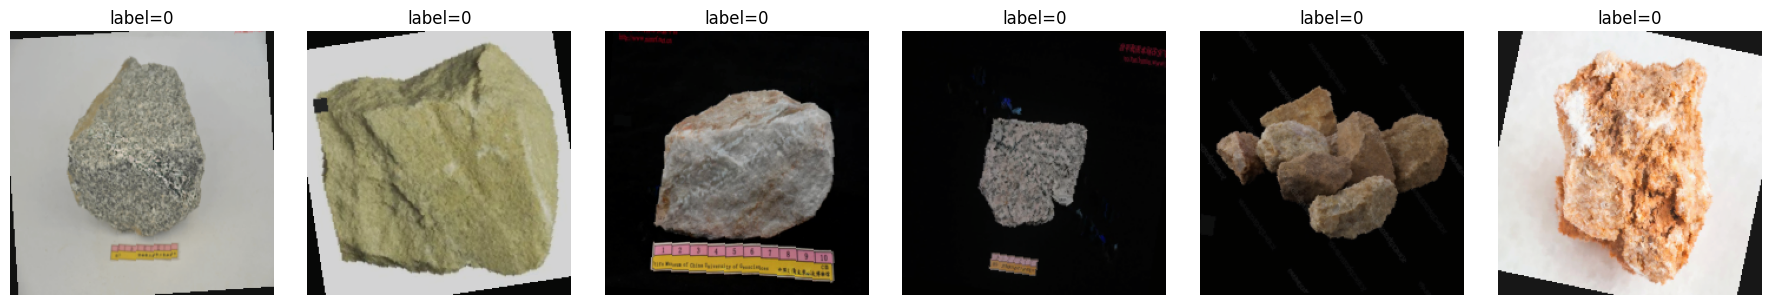

In [38]:
show_poison_examples(train_full_dataset, target_label=0, n=6)

## Check label distribution

Unique labels: 2
label
1    2685
0    2413
Name: count, dtype: int64


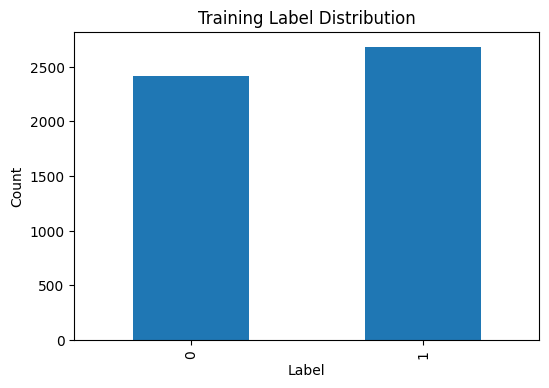

In [39]:
labels_df = pd.read_csv(os.path.join(DATA_ROOT, "train_labels.csv"))
print("Unique labels:", labels_df["label"].nunique())
print(labels_df["label"].value_counts())

plt.figure(figsize=(6, 4))
labels_df["label"].value_counts().sort_index().plot(kind="bar")
plt.title("Training Label Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

## Preview a few training images

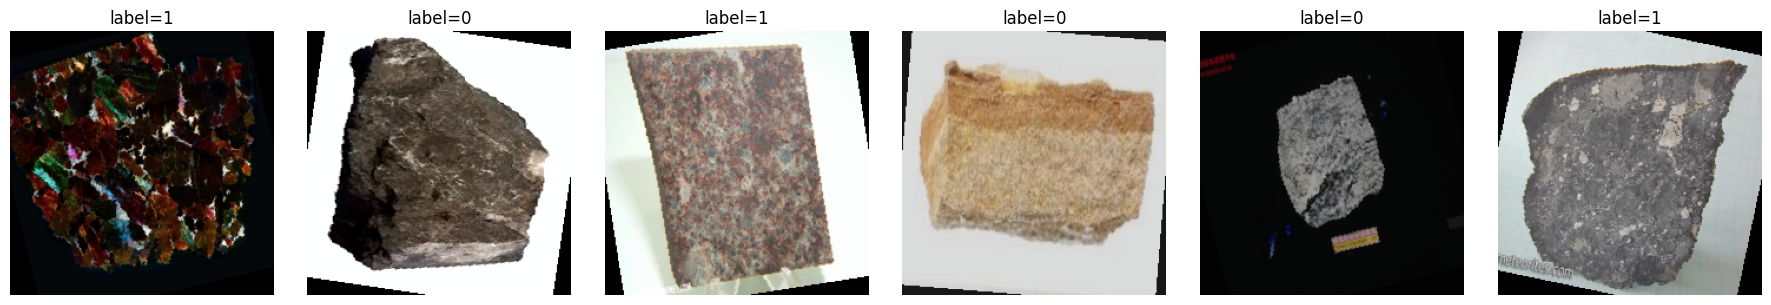

In [40]:
def show_batch(loader, n=6):
    images, labels = next(iter(loader))
    images = images[:n]
    labels = labels[:n]

    fig, axes = plt.subplots(1, n, figsize=(3*n, 3))
    if n == 1:
        axes = [axes]

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for ax, img, label in zip(axes, images, labels):
        img = img.permute(1, 2, 0).numpy()
        img = np.clip(img * std + mean, 0, 1)
        ax.imshow(img)
        ax.set_title(f"label={int(label)}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_batch(trainloader, n=6)

## Hyperparameter

In [41]:
num_classes = 2
epochs = 15
lr = 1e-4
weight_decay = 1e-4
use_pretrained = True
freeze_backbone = False

## Model
This notebook directly calls torchvision ResNet18 and replaces the final fully connected layer with a 2-class classifier.

In [42]:
from model import build_model

model = build_model(
    num_classes=num_classes,
    pretrained=use_pretrained
).to(device)

#print(model)

## Loss / optimizer / scheduler

In [43]:
class_counts = np.bincount(train_full_dataset.labels)
print(class_counts)   # 例如 [2415, 2683]

weights = torch.tensor([
    1.0 / class_counts[0],
    1.0 / class_counts[1]
], dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

[2413 2685]


In [44]:
#class_weights = torch.tensor([1.0, 1.5], dtype=torch.float).to(device)
#criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

## Train one epoch

In [45]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.detach().cpu().numpy().tolist())
        all_labels.extend(labels.detach().cpu().numpy().tolist())

    epoch_loss = total_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)

    return epoch_loss, epoch_f1

## Evaluate

In [46]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)

        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())

    epoch_loss = total_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)

    return epoch_loss, epoch_f1, all_labels, all_preds

In [47]:
@torch.no_grad()
def evaluate_with_probs(model, loader, criterion, device, threshold=0.5):
    model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)

        probs = torch.softmax(outputs, dim=1)[:, 1]   # class 1 probability
        preds = (probs >= threshold).long()

        all_probs.extend(probs.cpu().numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())

    epoch_loss = total_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)

    return epoch_loss, epoch_f1, all_labels, all_preds, all_probs

## Main training loop

In [48]:
print(f"Model device: {next(model.parameters()).device}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Current device: {device}")

Model device: cuda:0
CUDA available: True
Current device: cuda


In [49]:
train_losses = []
train_f1s = []
val_losses = []
val_f1s = []

best_val_f1 = -1.0
best_model_path = "method1_blacksquare_resnet18_best.pth"

start_time = time.time()

for epoch in range(epochs):
    # ====================== 加这一行 ======================
    #print(f"=== 开始第 {epoch+1} 轮训练 ===")

    train_loss, train_f1 = train_one_epoch(
        model=model,
        loader=trainloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # ====================== 加这一行 ======================
    #print(f"=== 第 {epoch+1} 轮训练完成，开始验证 ===")

    val_loss, val_f1, _, _ = evaluate(
        model=model,
        loader=valloader,
        criterion=criterion,
        device=device
    )

    scheduler.step()

    train_losses.append(train_loss)
    train_f1s.append(train_f1)
    val_losses.append(val_loss)
    val_f1s.append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_model_path)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val F1: {val_f1:.4f}"
    )

elapsed = time.time() - start_time
print(f"Training finished in {elapsed/60:.2f} minutes")
print(f"Best Val F1: {best_val_f1:.4f}")
print(f"Best model saved to: {best_model_path}")

Epoch [1/15] Train Loss: 0.1690 | Train F1: 0.9399 | Val Loss: 0.0515 | Val F1: 0.9615
Epoch [2/15] Train Loss: 0.0694 | Train F1: 0.9771 | Val Loss: 0.0406 | Val F1: 0.9662
Epoch [3/15] Train Loss: 0.0504 | Train F1: 0.9841 | Val Loss: 0.0188 | Val F1: 0.9852
Epoch [4/15] Train Loss: 0.0398 | Train F1: 0.9880 | Val Loss: 0.0300 | Val F1: 0.9703
Epoch [5/15] Train Loss: 0.0344 | Train F1: 0.9888 | Val Loss: 0.0144 | Val F1: 0.9802
Epoch [6/15] Train Loss: 0.0201 | Train F1: 0.9942 | Val Loss: 0.0368 | Val F1: 0.9756
Epoch [7/15] Train Loss: 0.0098 | Train F1: 0.9975 | Val Loss: 0.0629 | Val F1: 0.9524
Epoch [8/15] Train Loss: 0.0122 | Train F1: 0.9973 | Val Loss: 0.0547 | Val F1: 0.9615
Epoch [9/15] Train Loss: 0.0088 | Train F1: 0.9979 | Val Loss: 0.0324 | Val F1: 0.9706
Epoch [10/15] Train Loss: 0.0120 | Train F1: 0.9967 | Val Loss: 0.0223 | Val F1: 0.9804
Epoch [11/15] Train Loss: 0.0092 | Train F1: 0.9979 | Val Loss: 0.0524 | Val F1: 0.9479
Epoch [12/15] Train Loss: 0.0045 | Train 

## Plot training curves

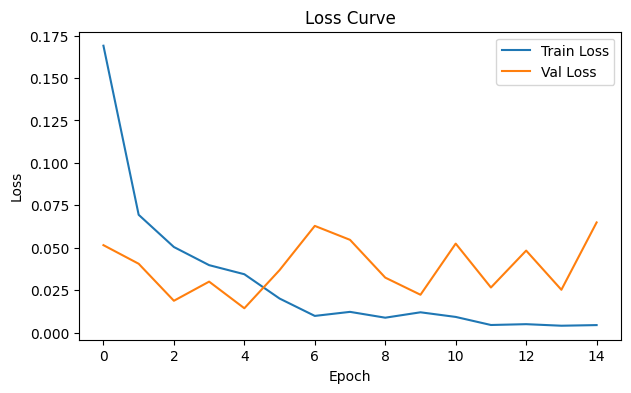

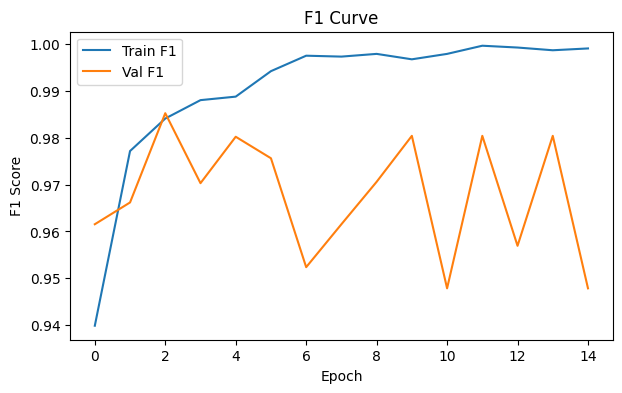

In [50]:
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()
plt.savefig("method1_blacksquare_resnet18_best_loss.png", dpi=150, bbox_inches="tight")  # 保存
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(train_f1s, label="Train F1")
plt.plot(val_f1s, label="Val F1")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("F1 Curve")
plt.legend()
plt.savefig("method1_blacksquare_resnet18_best_f1.png", dpi=150, bbox_inches="tight")    # 保存
plt.show()

## Load best model and evaluate again

In [51]:
model.load_state_dict(torch.load(best_model_path, map_location=device))

val_loss, val_f1, val_labels, val_preds = evaluate(
    model=model,
    loader=valloader,
    criterion=criterion,
    device=device
)

print(f"Best Model Val Loss: {val_loss:.4f}")
print(f"Best Model Val F1:   {val_f1:.4f}")

Best Model Val Loss: 0.0188
Best Model Val F1:   0.9852


In [52]:
import numpy as np
from sklearn.metrics import f1_score

val_loss, _, val_labels, _, val_probs = evaluate_with_probs(
    model=model,
    loader=valloader,
    criterion=criterion,
    device=device,
    threshold=0.5
)

best_thr = 0.5
best_f1 = -1

for thr in np.arange(0.1, 0.91, 0.01):
    preds = [1 if p >= thr else 0 for p in val_probs]
    f1 = f1_score(val_labels, preds)
    print(f"thr={thr:.2f}, f1={f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_thr = thr

print("\nBest threshold:", best_thr)
print("Best threshold F1:", best_f1)

thr=0.10, f1=0.9569
thr=0.11, f1=0.9615
thr=0.12, f1=0.9709
thr=0.13, f1=0.9709
thr=0.14, f1=0.9709
thr=0.15, f1=0.9709
thr=0.16, f1=0.9709
thr=0.17, f1=0.9709
thr=0.18, f1=0.9709
thr=0.19, f1=0.9709
thr=0.20, f1=0.9709
thr=0.21, f1=0.9756
thr=0.22, f1=0.9756
thr=0.23, f1=0.9756
thr=0.24, f1=0.9756
thr=0.25, f1=0.9756
thr=0.26, f1=0.9804
thr=0.27, f1=0.9804
thr=0.28, f1=0.9804
thr=0.29, f1=0.9804
thr=0.30, f1=0.9852
thr=0.31, f1=0.9852
thr=0.32, f1=0.9852
thr=0.33, f1=0.9852
thr=0.34, f1=0.9852
thr=0.35, f1=0.9852
thr=0.36, f1=0.9852
thr=0.37, f1=0.9852
thr=0.38, f1=0.9852
thr=0.39, f1=0.9852
thr=0.40, f1=0.9852
thr=0.41, f1=0.9852
thr=0.42, f1=0.9852
thr=0.43, f1=0.9852
thr=0.44, f1=0.9852
thr=0.45, f1=0.9852
thr=0.46, f1=0.9852
thr=0.47, f1=0.9852
thr=0.48, f1=0.9852
thr=0.49, f1=0.9852
thr=0.50, f1=0.9852
thr=0.51, f1=0.9852
thr=0.52, f1=0.9852
thr=0.53, f1=0.9852
thr=0.54, f1=0.9852
thr=0.55, f1=0.9852
thr=0.56, f1=0.9852
thr=0.57, f1=0.9852
thr=0.58, f1=0.9852
thr=0.59, f1=0.9852


In [53]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(val_labels, val_preds)
print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(val_labels, val_preds, digits=4))

Confusion Matrix:
[[397   3]
 [  0 100]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9925    0.9962       400
           1     0.9709    1.0000    0.9852       100

    accuracy                         0.9940       500
   macro avg     0.9854    0.9963    0.9907       500
weighted avg     0.9942    0.9940    0.9940       500



In [54]:
print("train size:", len(train_indices))
print("val size:", len(val_indices))
print("intersection size:", len(set(train_indices) & set(val_indices)))

train size: 4598
val size: 500
intersection size: 0


## Confusion matrix on validation set

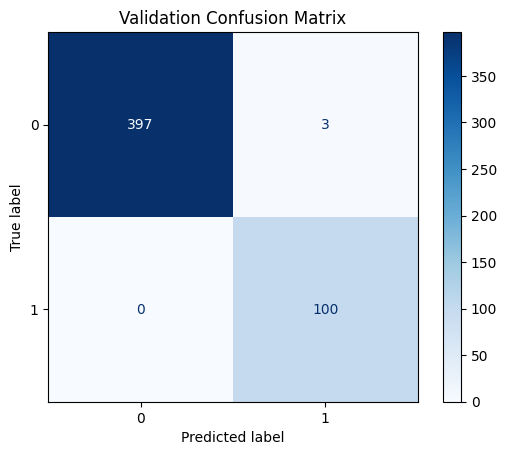

In [55]:
cm = confusion_matrix(val_labels, val_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap="Blues")
plt.title("Validation Confusion Matrix")
plt.show()

## Predict test set
This follows the same logic as the provided README: run model inference on `testloader`, then create a standard `submission.csv`.

In [56]:

@torch.no_grad()
def predict_with_threshold(model, loader, device, threshold=0.5):
    model.eval()
    id_to_pred = {}

    for images, img_paths in loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]   # 取 class 1 的概率
        preds = (probs >= threshold).long().cpu().numpy().tolist()

        for pred, path in zip(preds, img_paths):
            image_id = os.path.basename(path)
            id_to_pred[image_id] = int(pred)

    return id_to_pred


def make_submission(id_to_pred, template_csv_path, output_path):
    ids_df = pd.read_csv(template_csv_path)

    if "id" not in ids_df.columns:
        raise ValueError(f"{template_csv_path} must contain 'id' column")

    submission_df = ids_df.copy()
    submission_df["label"] = submission_df["id"].map(id_to_pred)

    if submission_df["label"].isna().any():
        missing_ids = submission_df.loc[submission_df["label"].isna(), "id"].head(5).tolist()
        raise RuntimeError(f"Missing predictions for some ids, examples: {missing_ids}")

    submission_df["label"] = submission_df["label"].astype(int)
    submission_df.to_csv(output_path, index=False)

## Generate submission.csv

In [57]:
id_to_pred = predict_with_threshold(
    model=model,
    loader=testloader,
    device=device,
    threshold=best_thr
)

submission_path = "method1_blacksquare_submission(back).csv"   # 直接保存在当前文件夹
template_csv_path = os.path.join(DATA_ROOT, "sample_submission.csv")

make_submission(
    id_to_pred=id_to_pred,
    template_csv_path=template_csv_path,
    output_path=submission_path
)

print(f"Submission file saved to: {submission_path}")
pd.read_csv(submission_path).head()

Submission file saved to: method1_blacksquare_submission(back).csv


,id,label
0,000001.jpg,0
1,000002.jpg,0
2,000003.jpg,0
3,000004.jpg,1
4,000005.jpg,0


In [58]:
import pandas as pd

sub = pd.read_csv(submission_path)
print(sub.head())
print(sub.shape)
print(sub["label"].value_counts())

           id  label
0  000001.jpg      0
1  000002.jpg      0
2  000003.jpg      0
3  000004.jpg      1
4  000005.jpg      0
(511, 2)
label
0    375
1    136
Name: count, dtype: int64


## Optional experiment log

In [59]:
results = [{
    "model": "resnet18",
    "pretrained": use_pretrained,
    "freeze_backbone": freeze_backbone,
    "epochs": epochs,
    "batch_size": batch_size,
    "lr": lr,
    "weight_decay": weight_decay,
    "best_val_f1": best_val_f1
}]

In [60]:
results_df = pd.DataFrame(results)
results_df

,model,pretrained,freeze_backbone,epochs,batch_size,lr,weight_decay,best_val_f1
0,resnet18,True,False,15,32,0.0001,0.0001,0.985222
